#### Data Analysis - CNT Filling with Fluorinated molecules

1. Basic functions

In [ ]:
# ==============================================================================
# [ CELL 1 ] : IMPORTS, DATA STRUCTURES, STYLE & CORE PIPELINE FUNCTIONS
# ==============================================================================
%matplotlib widget
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from dataclasses import dataclass

# --- 1. DATA STRUCTURE FOR RAMAN MEASUREMENTS ---
@dataclass
class RamanSpectrum:
    filename: str
    folder: str
    df: pd.DataFrame          # Columns: ['RamanShift', 'Intensity']
    label: str = ""
    laser: str = "Unknown"
    grating: str = "Unknown"
    color: str = "#000000"
    linestyle: str = "-"
    scale: float = 1.0        # Manual scaling factor (e.g., for free molecules)
    offset: float = 0.0       # Individual vertical offset

    def __post_init__(self):
        if not self.label:
            self.label = self.filename
        # Auto-extract laser and grating from standard Xplora filename
        laser_match = re.search(r'(532|638|785)\s*nm', self.filename, re.IGNORECASE)
        if laser_match:
            self.laser = f"{laser_match.group(1)} nm"
        grating_match = re.search(r'(\d{3,4})\s*gr', self.filename, re.IGNORECASE)
        if grating_match:
            self.grating = f"{grating_match.group(1)} gr/mm"

    def copy(self):
        return RamanSpectrum(
            filename=self.filename,
            folder=self.folder,
            df=self.df.copy(),
            label=self.label,
            laser=self.laser,
            grating=self.grating,
            color=self.color,
            linestyle=self.linestyle,
            scale=self.scale,
            offset=self.offset
        )

    @property
    def X(self):
        return self.df["RamanShift"].values

    @property
    def Y(self):
        return self.df["Intensity"].values

    @Y.setter
    def Y(self, new_y):
        self.df["Intensity"] = new_y


# --- 2. PUBLICATION / POSTER STYLE CONFIGURATION ---
poster_style = {
    "figsize": (4.2, 3.4),
    "dpi": 300,
    "font_size": 10,
    "title_size": 11,
    "label_size": 11,
    "legend_size": 8,
    "line_width": 1.2,
    "font_family": "Calibri",
    "grid": False,
    "colors": ["#000000", "#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9"],
    "linestyles": ["-", "--", "-.", ":"]
}


# --- 3. CORE PROCESSING FUNCTIONS (TRIM, BASELINE, NORMALIZE) ---
def TrimSpectrum(spec_obj, xmin=None, xmax=None):
    """Trims a single RamanSpectrum object to [xmin, xmax]."""
    s = spec_obj.copy()
    mask = np.ones_like(s.X, dtype=bool)
    if xmin is not None:
        mask &= (s.X >= xmin)
    if xmax is not None:
        mask &= (s.X <= xmax)
    s.df = s.df[mask].copy().reset_index(drop=True)
    return s

def SubtractBaseline(spec_obj, poly_order=1, anchor_windows=None):
    """
    Subtracts a baseline from the spectrum.
    - poly_order:0 (minimum value subtraction), 1 (linear), 2+ (polynomial).
    - anchor_windows: list of tuples [(xmin1, xmax1), (xmin2, xmax2)] containing baseline-only regions.
                      If None, uses the first and last 5% of the spectrum.
    """
    s = spec_obj.copy()
    X, Y = s.X, s.Y
    if len(X) == 0:
        return s

    if poly_order == 0:
        s.Y = Y - np.min(Y)
        return s

    if anchor_windows is None:
        n_pts = max(3, int(len(X) * 0.05))
        mask = np.zeros_like(X, dtype=bool)
        mask[:n_pts] = True
        mask[-n_pts:] = True
    else:
        mask = np.zeros_like(X, dtype=bool)
        for wmin, wmax in anchor_windows:
            mask |= ((X >= wmin) & (X <= wmax))

    if np.sum(mask) > poly_order:
        coeffs = np.polyfit(X[mask], Y[mask], poly_order)
        baseline = np.polyval(coeffs, X)
        s.Y = Y - baseline
    return s

def NormalizeSpectrum(spec_obj, xmin=None, xmax=None, mode="M", subtract_min_first=True):
    """
    Normalizes a single RamanSpectrum object within [xmin, xmax].
    - mode: 'M' (Maximum in window, e.g., G-band), 'I' (Integrated area), 'V' (Minimum), 'NONE' (No norm).
    - subtract_min_first: If True, shifts the window minimum to zero before normalizing.
    """
    s = spec_obj.copy()
    if mode is None or mode.upper() == "NONE":
        return s

    X, Y = s.X, s.Y
    mask = np.ones_like(X, dtype=bool)
    if xmin is not None:
        mask &= (X >= xmin)
    if xmax is not None:
        mask &= (X <= xmax)

    X_win, Y_win = X[mask], Y[mask]
    if len(X_win) == 0:
        return s

    if subtract_min_first:
        min_val = np.min(Y_win)
        Y = Y - min_val
        Y_win = Y_win - min_val

    mode = mode.upper()
    if mode == "M":
        factor = np.max(Y_win)
    elif mode == "I":
        factor = np.trapezoid(Y_win, X_win)
    elif mode == "V":
        factor = np.min(Y_win)
    else:
        raise ValueError("Mode must be 'M', 'I', 'V', or 'NONE'")

    if factor != 0:
        s.Y = Y / factor
    return s

2. Loading all data, then I will select the data to compare in excel.

In [52]:
# ==============================================================================
# [ CELDA 2 ] : SMART DATA LOADER (EXCEL-READY CATALOG)
# ==============================================================================

BASE_RAMAN_DIR = r"H:\FUBerlin\Measurements\Raman Xplora\CristianB"

def LoadRamanData(base_dir=BASE_RAMAN_DIR, sub_folders="ALL", inject_globals=True, print_catalog=True):
    """
    Loads Raman .txt files from the specified base directory.
    - sub_folders: "ALL" to scan every folder, or a list of folder names/keywords.
    - inject_globals: Creates clean Python variables for Tab-autocompletion.
    """
    spectra_dict = {}
    var_map = {}

    if not os.path.exists(base_dir):
        print(f"⚠️ Warning: Directory not found -> {base_dir}")
        return spectra_dict, var_map

    # Determine which folders to scan
    if sub_folders == "ALL":
        target_paths = [base_dir]
    else:
        target_paths = []
        for item in os.listdir(base_dir):
            full_p = os.path.join(base_dir, item)
            if os.path.isdir(full_p) and any(k.lower() in item.lower() for k in sub_folders):
                target_paths.append(full_p)

    for t_path in target_paths:
        for root, dirs, files in os.walk(t_path):
            folder_name = os.path.basename(root)
            for file in sorted(files):
                if not file.lower().endswith(".txt"):
                    continue
                path = os.path.join(root, file)
                try:
                    df = pd.read_csv(path, sep="\t", comment="#", header=None, encoding="latin1", usecols=[0, 1])
                    df.columns = ["RamanShift", "Intensity"]
                    df["RamanShift"] = pd.to_numeric(df["RamanShift"], errors="coerce")
                    df["Intensity"] = pd.to_numeric(df["Intensity"], errors="coerce")
                    df = df.dropna().sort_values("RamanShift").reset_index(drop=True)

                    if len(df) == 0:
                        continue

                    spec_obj = RamanSpectrum(filename=file, folder=folder_name, df=df)
                    spectra_dict[file] = spec_obj

                    # Create clean Python variable name
                    clean_var = "R_" + re.sub(r'\W+', '_', os.path.splitext(file)[0])
                    var_map[clean_var] = file
                    if inject_globals:
                        globals()[clean_var] = spec_obj

                except Exception as e:
                    pass

    # --- IMPRESIÓN FORMATO EXCEL (Separado por Tabulaciones) ---
    if print_catalog and len(spectra_dict) > 0:
        print(f"✅ Successfully loaded {len(spectra_dict)} Raman spectra.\n")
        print("================================================================================")
        print("📂 LOADED SPECTRA CATALOG (Excel-Ready Format)")
        print("================================================================================")
        
        # Cabecera para Excel separada por tabulaciones (\t)
        print("Folder\tLaser\tGrating\tSample\tFilename_for_Config")
        
        # Ordenamos la lista por Láser y luego por nombre de archivo
        sorted_files = sorted(spectra_dict.values(), key=lambda x: (x.laser, x.filename))
        
        for obj in sorted_files:
            # Extracción limpia del nombre de la muestra para usar como filtro en Excel
            sample_match = re.search(r'^\d{6}_(.*?)(?:_532|_638|_785)', obj.filename, re.IGNORECASE)
            if sample_match:
                sample_name = sample_match.group(1).strip('_')
            else:
                parts = obj.filename.split('_')
                sample_name = parts[1] if len(parts) > 1 else "Unknown"
                
            # Se imprime con \t para que Excel lo divida en columnas, y el nombre de archivo con comillas simples ''
            print(f"{obj.folder}\t{obj.laser}\t{obj.grating}\t{sample_name}\t'{obj.filename}'")
            
        print("================================================================================")

    return spectra_dict, var_map

def SearchSpectra(spectra_dict, *keywords):
    """Helper to filter and print filenames matching all given keywords."""
    matches = [fname for fname in spectra_dict if all(k.lower() in fname.lower() for k in keywords)]
    print(f"🔍 Found {len(matches)} matches for {keywords}:")
    for m in matches:
        print(f"    ('{m}', 'Label', '#000000', '-', 1.0, None),")
    return matches


# --- EXECUTE DATA LOADING ---
# Opción A: Cargar TODO
raman_spectra, raman_vars = LoadRamanData(BASE_RAMAN_DIR, sub_folders="ALL", print_catalog=True)

# Opción B: Cargar solo ciertas fechas o carpetas
# raman_spectra, raman_vars = LoadRamanData(BASE_RAMAN_DIR, sub_folders=["20260909", "20260911"], print_catalog=True)

✅ Successfully loaded 165 Raman spectra.

📂 LOADED SPECTRA CATALOG (Excel-Ready Format)
Folder	Laser	Grating	Sample	Filename_for_Config
532nm	532 nm	1800 gr/mm	6FBz	'260529_6FBz_532 nm_1800gr_x10_1%_3_120_50_100.txt'
532nm	532 nm	1800 gr/mm	F005AP_6FBz@P2Sol	'260529_F005AP_6FBz@P2Sol_532 nm_1800gr_x10_1%_3_120_50_100.txt'
532nm	532 nm	1800 gr/mm	F005LP_6FBz@P2Sol	'260529_F005LP_6FBz@P2Sol_532 nm_1800gr_x10_1%_3_120_50_100.txt'
532nm	532 nm	1800 gr/mm	P2ReferenceSol	'260529_P2ReferenceSol_532 nm_1800gr_x10_1%_3_120_50_100.txt'
532nm	532 nm	600 gr/mm	6FBz	'260605_6FBz_532 nm_600gr_x10_1%_3_10_50_100_sc2700.txt'
532nm	532 nm	600 gr/mm	F005AP_6FBz@P2Sol_CF260528	'260605_F005AP_6FBz@P2Sol_CF260528_532 nm_600gr_x10_1%_3_10_50_100_sc2700.txt'
532nm	532 nm	600 gr/mm	F005LP_6FBz@P2Sol_CF260528	'260605_F005LP_6FBz@P2Sol_CF260528_532 nm_600gr_x10_1%_3_10_50_100_sc2700.txt'
532nm	532 nm	600 gr/mm	F006WA_phDADQ@P2Sol_CF260605	'260605_F006WA_phDADQ@P2Sol_CF260605_532 nm_600gr_x10_1%_3_10_50_100_sc27

3. Plotting Function

In [53]:
# ==============================================================================
# [ CELL 3 ] : FLEXIBLE PLOTTING ENGINE (SUPPORTS FREE MOLECULE RESCALING)
# ==============================================================================

def PlotRamanConfig(
    config, spectra_dict=None, style=poster_style, offset_step=0.0,
    xmin=None, xmax=None, ymin=None, ymax=None,
    norm_xmin=None, norm_xmax=None, norm_mode="M", subtract_min_first=True,
    vlines=None, rbm_laser_nm=None, hide_yticks=True, legend_ncol=1,
    title=None, save_path=None
):
    """
    Plots a list of spectra with full control over individual scaling and trimming.
    
    Each tuple in `config` can have 4, 5, or 6 elements:
      1. (file_or_obj, label, color, linestyle)
      2. (file_or_obj, label, color, linestyle, manual_scale)
      3. (file_or_obj, label, color, linestyle, manual_scale, (ind_xmin, ind_xmax))
         -> Note: If manual_scale != 1.0, you can also pass 'RAW' or a tuple to skip global normalization
            or scale it relative to the normalized peak!
    """
    fig, ax = plt.subplots(figsize=style["figsize"], dpi=style["dpi"])
    plt.rcParams.update({"font.size": style["font_size"], "font.family": style["font_family"]})

    processed_list = []

    for i, item in enumerate(config):
        # Unpack tuple flexibly (supports 4, 5, or 6 items)
        source, label, color, ls = item[0], item[1], item[2], item[3]
        manual_scale = item[4] if len(item) > 4 else 1.0
        ind_trim = item[5] if len(item) > 5 else None

        # Retrieve RamanSpectrum object
        if isinstance(source, RamanSpectrum):
            s = source.copy()
        elif isinstance(source, str) and spectra_dict and source in spectra_dict:
            s = spectra_dict[source].copy()
        else:
            print(f"⚠️ Spectrum not found: {source}")
            continue

        # 1. Global Normalization (e.g., G-band between 1500 and 1650 cm-1)
        if norm_mode and norm_mode.upper() != "NONE":
            s = NormalizeSpectrum(s, xmin=norm_xmin, xmax=norm_xmax, mode=norm_mode, subtract_min_first=subtract_min_first)

        # 2. Global Trim
        if xmin is not None or xmax is not None:
            s = TrimSpectrum(s, xmin=xmin, xmax=xmax)

        # 3. Individual Trim (e.g., cut noisy region of free molecule spectrum)
        if ind_trim is not None:
            s = TrimSpectrum(s, xmin=ind_trim[0], xmax=ind_trim[1])

        # 4. Apply Manual Scale Factor & Offset
        s.Y = (s.Y * manual_scale) + (i * offset_step)
        s.label = label
        s.color = color
        s.linestyle = ls
        processed_list.append(s)

        # Plot curve
        ax.plot(s.X, s.Y, label=s.label, color=s.color, linestyle=s.linestyle, linewidth=style["line_width"])

    ax.set_xlabel("Raman shift (cm$^{-1}$)", fontsize=style["label_size"])
    ax.set_ylabel("Intensity (a.u.)", fontsize=style["label_size"])

    if xmin is not None or xmax is not None:
        ax.set_xlim(xmin, xmax)
    if ymin is not None or ymax is not None:
        ax.set_ylim(ymin, ymax)
    if style.get("grid", False):
        ax.grid(True, alpha=0.3)
    if hide_yticks:
        ax.set_yticklabels([])
        ax.set_yticks([])

    # Optional vertical reference lines (e.g., pristine G+ or molecule peaks)
    if vlines is not None:
        for x_val in vlines:
            ax.axvline(x=x_val, linewidth=0.7, linestyle='--', color='#555555', alpha=0.8, zorder=0)

    # Optional top axis showing SWCNT Diameter (nm) if plotting the RBM region (100 - 400 cm-1)
    if rbm_laser_nm is not None or (xmin is not None and xmax is not None and xmax <= 450):
        ax_top = ax.twiny()
        ax_top.set_xlim(ax.get_xlim())
        rbm_ticks = np.array([150, 200, 250, 300, 350])
        rbm_ticks = rbm_ticks[(rbm_ticks >= ax.get_xlim()[0]) & (rbm_ticks <= ax.get_xlim()[1])]
        # Standard relation: omega_RBM = 228 / d_t + 16
        diam_labels = [f"{228.0 / (w - 16.0):.2f}" for w in rbm_ticks]
        ax_top.set_xticks(rbm_ticks)
        ax_top.set_xticklabels(diam_labels, fontsize=style["font_size"] - 1)
        ax_top.set_xlabel("SWCNT Diameter $d_t$ (nm)", fontsize=style["label_size"] - 1)

    if title:
        ax.set_title(title, fontsize=style["title_size"])

    ax.legend(fontsize=style["legend_size"], ncol=legend_ncol, frameon=False)
    plt.tight_layout()

    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, dpi=style["dpi"], bbox_index="tight")
        print(f"💾 Saved figure to: {save_path}")

    plt.show()
    return processed_list

## 532nm Data - FluorinatedMol@CNTs vs References (Water-filled, Empty, Alkanes, etc...)

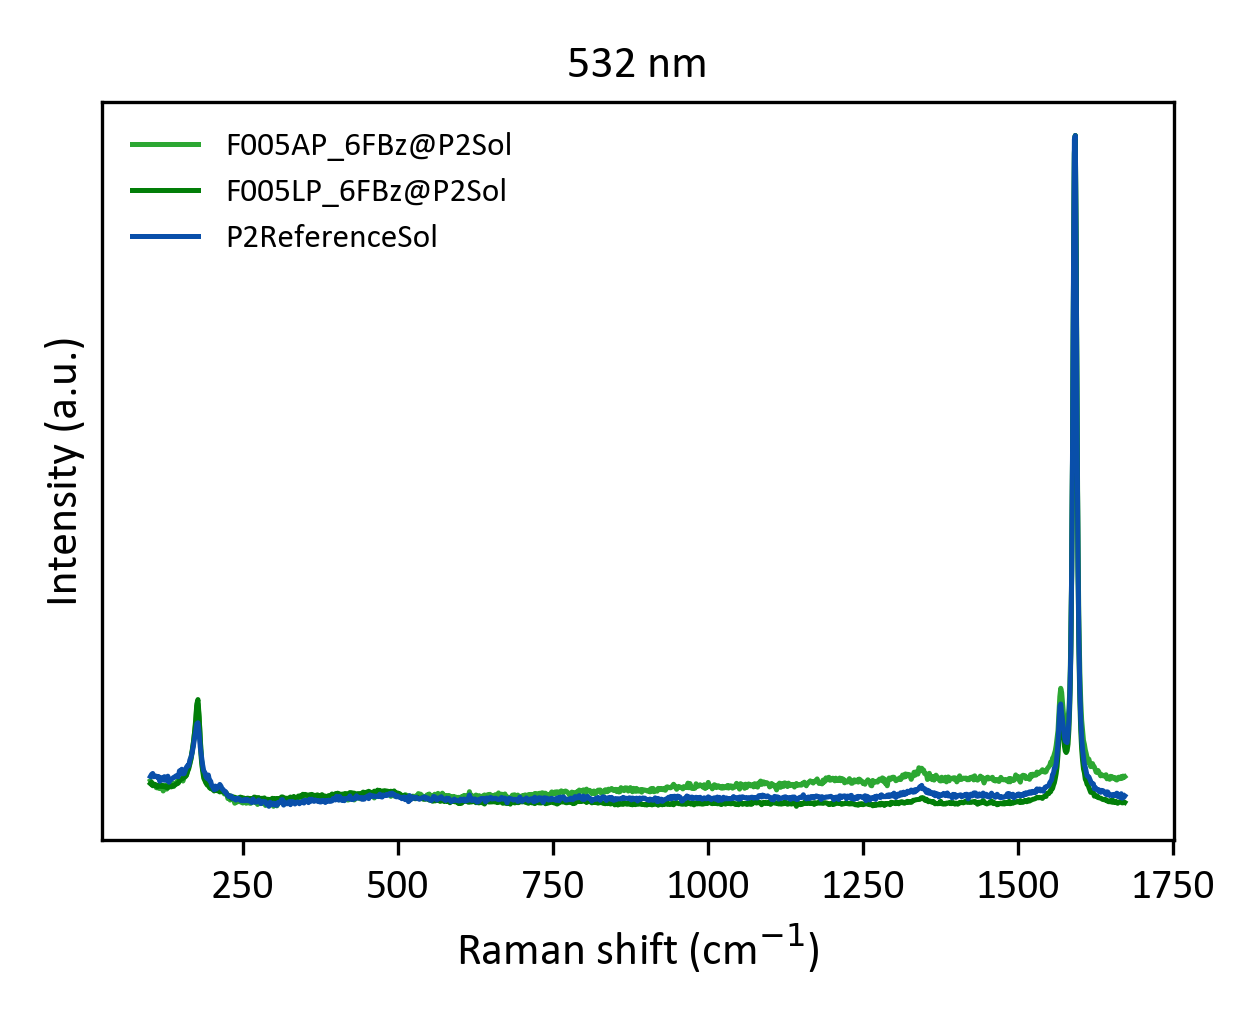

[RamanSpectrum(filename='260529_F005AP_6FBz@P2Sol_532 nm_1800gr_x10_1%_3_120_50_100.txt', folder='532nm', df=     RamanShift  Intensity
 0       100.860   0.038075
 1       102.742   0.035088
 2       104.622   0.032759
 3       106.504   0.033318
 4       108.385   0.032223
 ..          ...        ...
 945    1667.110   0.044465
 946    1668.550   0.041777
 947    1670.000   0.045076
 948    1671.440   0.043109
 949    1672.880   0.044181
 
 [950 rows x 2 columns], label='F005AP_6FBz@P2Sol', laser='532 nm', grating='1800 gr/mm', color='#2CA732', linestyle='-', scale=1.0, offset=0.0),
 RamanSpectrum(filename='260529_F005LP_6FBz@P2Sol_532 nm_1800gr_x10_1%_3_120_50_100.txt', folder='532nm', df=     RamanShift  Intensity
 0       100.860   0.033858
 1       102.742   0.035870
 2       104.622   0.030688
 3       106.504   0.031407
 4       108.385   0.032670
 ..          ...        ...
 945    1667.110   0.007175
 946    1668.550   0.005118
 947    1670.000   0.005318
 948    1671.440   0

In [54]:
config_532_comparison = [

#('260529_6FBz_532 nm_1800gr_x10_1%_3_120_50_100.txt', '6FBz', "#7B867C", '-', 0.1, (0, 1000)),
('260529_F005AP_6FBz@P2Sol_532 nm_1800gr_x10_1%_3_120_50_100.txt', 'F005AP_6FBz@P2Sol', "#2CA732", '-'),
('260529_F005LP_6FBz@P2Sol_532 nm_1800gr_x10_1%_3_120_50_100.txt', 'F005LP_6FBz@P2Sol', '#027E08', '-'),
('260529_P2ReferenceSol_532 nm_1800gr_x10_1%_3_120_50_100.txt', 'P2ReferenceSol', '#094FAA', '-'),

#('260605_6FBz_532 nm_600gr_x10_1%_3_10_50_100_sc2700.txt', '6FBz', '#000000', '-'),
#('260605_F005AP_6FBz@P2Sol_CF260528_532 nm_600gr_x10_1%_3_10_50_100_sc2700.txt', 'F005AP_6FBz@P2Sol_CF260528', '#2CA732', '-'),
#('260605_F005LP_6FBz@P2Sol_CF260528_532 nm_600gr_x10_1%_3_10_50_100_sc2700.txt', 'F005LP_6FBz@P2Sol_CF260528', '#027E08', '-'),
#('260605_P2_RefSol_NS_CF260529_532 nm_600gr_x10_1%_3_10_50_100_sc2700.txt', 'P2_RefSol_NS_CF260529', '#094FAA', '-'),
#('260605_P2_RefSol_TSR2_CF260224_532 nm_600gr_x10_1%_3_10_50_100_sc2700.txt', 'P2_RefSol_TSR2_CF260224', "#094FAA", '-'),

#('260818_F005LP_6FBz@P2_CFDrop_532 nm_1200gr_x50 LD_0_1%_3_20_100_300_sc1350.txt', 'F005LP_6FBz@P2_CFDrop', '#027E08', '-'),
#('260818_F005LP_6FBz@P2_CFDrop_532 nm_1800gr_x50 LD_0_1%_3_20_100_300_sc2150.txt', 'F005LP_6FBz@P2_CFDrop', '#027E08', '-'),
#('260818_F005LP_6FBz@P2_CFDrop_532 nm_1800gr_x50 LD_0_1%_3_20_100_300_sc875.txt', 'F005LP_6FBz@P2_CFDrop', '#027E08', '-'),
#('260818_F007WA_1BrC18@P2_CFDrop_532 nm_1200gr_x50 LD_0_1%_3_20_100_300_sc1350.txt', 'F007WA_1BrC18@P2_CFDrop', '#000000', '-'),
#('260818_F007WA_1BrC18@P2_CFDrop_532 nm_1800gr_x50 LD_0_1%_3_20_100_300_sc2150.txt', 'F007WA_1BrC18@P2_CFDrop', '#000000', '-'),
#('260818_F007WA_1BrC18@P2_CFDrop_532 nm_1800gr_x50 LD_0_1%_3_20_100_300_sc875.txt', 'F007WA_1BrC18@P2_CFDrop', '#000000', '-'),
#('260818_P2_CFDrop_532 nm_1200gr_x50 LD_0_1%_3_20_100_300_sc1350.txt', 'P2_CFDrop', '#094FAA', '-'),
#('260818_P2_CFDrop_532 nm_1800gr_x50 LD_0_1%_3_20_100_300_sc2150.txt', 'P2_CFDrop', '#094FAA', '-'),
#('260818_P2_CFDrop_532 nm_1800gr_x50 LD_0_1%_3_20_100_300_sc875.txt', 'P2_CFDrop', '#094FAA', '-'),

]


PlotRamanConfig(
    config=config_532_comparison,
    spectra_dict=raman_spectra,
    offset_step=-0.0,
    #xmin=100, xmax=2800,
    #norm_xmin=1550, norm_xmax=1620, norm_mode="M",  # Normalize all to G-band maximum
    #vlines=[1592],                                  # Vertical guide on pristine G+ peak
    hide_yticks=True,
    title="532 nm"
)
